# **Problem Statement**

## Business Context

In last-mile logistics, roughly 10% of all shipments encounter delivery exceptions - failed attempts, address mismatches, damaged packages, refused deliveries, and weather delays. Each failed delivery costs in direct reattempt expenses, while the downstream impact is far steeper: consumers stop shopping with a retailer after just 2-3 failed deliveries, and supply chain disruptions cost companies millions per year.

Despite these costs, most organizations still handle exception triage and resolution manually. Operations staff read through status logs and messy driver notes, cross-reference customer profiles and internal playbooks, decide on a resolution action, and draft customer notifications - all under time pressure. Teams rely on support tickets, tribal knowledge, and rigid rule engines that cannot handle the nuanced, multi-factor judgment calls that real exceptions demand. A VIP customer with a perishable package and a broken gate code on a second attempt requires a fundamentally different resolution than a standard customer's first failed attempt on a non-perishable item - but manual processes treat them with the same slow, inconsistent workflow.

Key KPIs affected include:
- Exception resolution time (constrained by manual triage throughput)
- Escalation accuracy (missed or unnecessary supervisor escalations)
- Customer communication quality and personalization
- Cost per exception (reattempt costs, spoilage write-offs, unnecessary truck rolls)
- Customer retention and lifetime value

If unaddressed, logistics providers face rising exception-handling costs, inconsistent service quality, preventable customer churn, and loss of competitive ground to players who are already investing in AI-powered exception detection and response automation.

By applying an AI-powered multi-agent system that ingests delivery logs, cross-references customer profiles and locker availability, retrieves resolution policy from an operational playbook, and generates validated decisions with personalized customer communications, logistics providers can automate the full exception-handling pipeline from detection through resolution, with built-in quality validation and supervisor escalation where policy requires it.


## Objective

The objective is to build a POC of an AI-powered multi-agent delivery exception handling system for the last-mile delivery operations of a mid-sized retailer that:
- uses the operator's available data to process exceptions end-to-end,
- ingests raw delivery status logs, including noisy, duplicated, and multi-row shipment events, and correctly identifies actionable exceptions versus routine operational noise,
- decides the appropriate resolution action (reschedule, reroute to locker, replace, or return to sender) by reasoning over playbook rules, customer context, package constraints, and locker eligibility, while respecting operational policies around perishable handling, fragile thresholds, and locker capacity.
- escalates to a human supervisor when policy requires it and avoids unnecessary escalations that waste supervisor capacity,
- generates personalized customer notifications with tone, channel, and content calibrated to customer tier and exception severity, and
- produces auditable decisions with step-by-step rationale, critical validation traces, and system evaluation metrics across five dimensions: task completion rate, escalation accuracy, tool call accuracy, reasoning trajectory coherence, and end-to-end latency.

The end goal is to demonstrate measurable accuracy and consistency on curated exception scenarios sufficient to justify scaling the approach to real-time operations with live delivery feeds, broader exception taxonomies, and multi-region deployment.


## Data Dictionary

The data comprises three types of files.

### SQLite Database (`customers.db`)

**Table: `customers`** - 12 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| customer_id | string | Primary key (`CUST-001` to `CUST-012`), Foreign key in delivery logs |
| name | string | Customer full name (**PII**) |
| tier | string | STANDARD, PREMIUM, VIP |
| preferred_channel | string | SMS, EMAIL |
| exceptions_last_90d | integer | Range: 0-6 |
| active_credit | float | Range: \$0.00-\$20.00 |

**Table: `lockers`** - 6 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| locker_id | string | Primary key (`LOC-001` to `LOC-006`) |
| address | string | Locker street address |
| zip_code | string | 10001-10006 |
| capacity_status | string | AVAILABLE, LIMITED, FULL |
| operating_hours | string | e.g., "6AM-10PM" or "24 hours" |
| max_package_size | string | SMALL, MEDIUM, LARGE |

### CSV Files

**Delivery Status Logs (`delivery_logs.csv`)** - 13 rows, 10 unique shipments

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | `SHP-001` to `SHP-01`0, Multiple rows may share the same ID for multi-event shipments. |
| timestamp | datetime | ISO format |
| status_code | string | One of seven codes: DELIVERED, ATTEMPTED, DAMAGED, ADDRESS_ISSUE, REFUSED, WEATHER_DELAY, SCANNED |
| status_description | string | Free-text driver/handler notes |
| customer_id | string | Foreign key to `customers` table (`CUST-001` to `CUST-012`) |
| delivery_address | string | Full address including zip code |
| package_type | string | STANDARD, PERISHABLE, FRAGILE |
| package_size | string | SMALL, MEDIUM, LARGE |
| attempt_number | integer | 0 for pre-delivery scans, 1+ for delivery attempts |
| is_duplicate_scan | boolean | True for repeated scan events |

**Ground Truth Labels (`ground_truth.csv`)** - 13 rows, aligned 1:1 with delivery logs

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | Matches delivery logs (`SHP-001` to `SHP-010`) |
| is_exception | string | YES, NO |
| expected_resolution | string | RESCHEDULE, REPLACE, REROUTE_TO_LOCKER, RETURN_TO_SENDER, N/A |
| expected_tone | string | FORMAL, CASUAL, N/A |
| should_escalate | string | YES, NO, N/A |
| ground_truth_reasoning | string | Step-by-step justification tracing each label to specific playbook rules, customer attributes, and locker constraints |

### Exception Resolution Playbook (`exception_resolution_playbook.pdf`)

An internal operations manual for human dispatchers in natural language.

# **Please read the instructions carefully before starting the project.**

This is a Python Notebook file with blocks of code pre-filled in alignment with a possible solution for the business use case at hand, and some blank sections where the code has to be written from scratch.

* Please feel free to
    * leverage the pre-filled code blocks as they are, or
    * update the pre-filled code blocks to incorporate necessary changes as per your desired solution workflow for the business problem at hand, or
    * discard the pre-filled code blocks and write the entire code from scratch
* Notebook sections and code blocks that contain instructions and tasks to be performed are mentioned.
* Blanks '\_\_\_\_\_' are provided in the notebook that need to be filled with an appropriate code to get the correct result.
    * With every '\_\_\_\_\_' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Please sequentially run the code cells from the beginning to avoid any unnecessary errors.
* Add the results/observations derived from the analysis under the respective notebook sections as per the grading rubric requirements.

# **Installing and Importing Necessary Libraries and Dependencies**

In [1]:
# Install into the active notebook kernel so Colab and Jupyter use the same environment
# Keep saved output free of machine-specific pip upgrade notices.
import os as _install_os
_install_os.environ["PIP_DISABLE_PIP_VERSION_CHECK"] = "1"

%pip -q install \
    langchain==1.2.10 \
    langchain-openai==1.1.10 \
    langgraph==1.0.8 \
    langsmith==0.7.3 \
    langchain-community==0.4.1 \
    langchain-huggingface==1.2.0 \
    openai==2.21.0 \
    pandas==2.2.2 \
    numpy==1.26.4 \
    scikit-learn==1.6.1 \
    scipy==1.14.1 \
    sentence-transformers==5.2.3 \
    pydantic==2.12.3 \
    langchain-chroma \
    langchain-text-splitters \
    pypdf

Note: you may need to restart the kernel to use updated packages.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for VSCode/Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# Standard library - paths, credentials, files, timing, databases, and collections
import csv
import json
import os
import re
import sqlite3
import time
import warnings
from collections import defaultdict
from pathlib import Path
from typing import Literal, Optional, TypedDict

# Data handling and notebook display
import pandas as pd
from IPython.display import Image, display

# Pydantic - typed and validated model outputs
from pydantic import BaseModel, Field, model_validator

# LangChain - model interface, messages, documents, and tools
from langchain_openai import ChatOpenAI
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool

# Document processing and retrieval
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from pypdf import PdfReader

# Agent orchestration and tracing
from langgraph.graph import END, StateGraph
from langsmith import traceable

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found.*")
print("Libraries imported successfully.")

Libraries imported successfully.


# **LLM and Agent Observability Setup**

We load all OpenAI and LangSmith credentials from a secure `config.json` file and store them as environment variables.

In [3]:
# Load the configuration file
file_name = "config.json"
with open(file_name, "r", encoding="utf-8") as file:
    config = json.load(file)

OPENAI_API_KEY = config.get("OPENAI_API_KEY")
OPENAI_BASE_URL = config.get("OPENAI_BASE_URL")

if not OPENAI_API_KEY:
    raise RuntimeError("Add OPENAI_API_KEY to config.json before running the notebook.")

# Store the OpenAI settings in environment variables
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
if OPENAI_BASE_URL:
    os.environ["OPENAI_BASE_URL"] = OPENAI_BASE_URL

# LangSmith tracing is optional
LANGCHAIN_TRACING_V2 = str(config.get("LANGCHAIN_TRACING_V2", "false")).lower()
LANGCHAIN_API_KEY = config.get("LANGCHAIN_API_KEY")
LANGCHAIN_PROJECT = config.get("LANGCHAIN_PROJECT", "last-mile-delivery-agents")

os.environ["LANGCHAIN_TRACING_V2"] = LANGCHAIN_TRACING_V2
if LANGCHAIN_API_KEY:
    os.environ["LANGCHAIN_API_KEY"] = LANGCHAIN_API_KEY
    os.environ["LANGCHAIN_PROJECT"] = LANGCHAIN_PROJECT


In [4]:
# Keep the course models as defaults, while allowing a different model through environment variables
GEN_MODEL = os.getenv("GEN_MODEL", "gpt-4o-mini")
VAL_MODEL = os.getenv("VAL_MODEL", "gpt-4o")
TEMPERATURE = 0

# The generation model handles classification, resolution, and customer messages
gen_llm = ChatOpenAI(
    model=GEN_MODEL,
    temperature=TEMPERATURE,
    max_retries=2,
)

# The stronger validation model handles both critics and the coherence judge
eval_llm = ChatOpenAI(
    model=VAL_MODEL,
    temperature=TEMPERATURE,
    max_retries=2,
)

print(f"Generation model: {GEN_MODEL}")
print(f"Validation model: {VAL_MODEL}")

Generation model: gpt-4o-mini
Validation model: gpt-4o


# **Data Loading and Vector Database Setup**

## Loading the CSV files

In [5]:
# The notebook runs directly from the project folder by default.
# In Colab, either change into that Drive folder first or set LAST_MILE_DATA_DIR.
data_dir_setting = os.getenv("LAST_MILE_DATA_DIR", "Datasets Last-Mile Delivery")
DATA_DIR = Path(data_dir_setting).expanduser()
if not DATA_DIR.is_absolute():
    DATA_DIR = (Path.cwd() / DATA_DIR).resolve()

DELIVERY_LOGS_PATH = DATA_DIR / "delivery_logs.csv"
GROUND_TRUTH_PATH = DATA_DIR / "ground_truth.csv"
CUSTOMERS_DB_PATH = DATA_DIR / "customers.db"
PLAYBOOK_PDF_PATH = DATA_DIR / "exception_resolution_playbook.pdf"

required_files = [
    DELIVERY_LOGS_PATH,
    GROUND_TRUTH_PATH,
    CUSTOMERS_DB_PATH,
    PLAYBOOK_PDF_PATH,
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required project files were not found. Set LAST_MILE_DATA_DIR to the data folder. "
        f"Missing: {missing_files}"
    )

# Load both CSV files for inspection and later evaluation
delivery_logs_df = pd.read_csv(DELIVERY_LOGS_PATH)
ground_truth_df = pd.read_csv(GROUND_TRUTH_PATH)

print(f"Data folder: {DATA_DIR}")
print(
    f"Delivery logs: {len(delivery_logs_df)} rows, "
    f"{delivery_logs_df['shipment_id'].nunique()} unique shipments"
)
print(f"Ground truth: {len(ground_truth_df)} rows")
display(delivery_logs_df)
display(ground_truth_df.fillna("N/A"))

Data folder: /Users/pradeeptathineni/Documents/EDUCATION/UT McCombs AI ML/Projects/6 - AI Agents for Automation/Datasets Last-Mile Delivery
Delivery logs: 13 rows, 10 unique shipments
Ground truth: 13 rows


,shipment_id,timestamp,status_code,status_description,customer_id,delivery_address,package_type,package_size,attempt_number,is_duplicate_scan
0,SHP-001,2026-03-05T10:14:00,DELIVERED,"Left at front door, signed by resident",CUST-003,"27 Maple Drive, Greenfield, 10001",STANDARD,SMALL,1,False
1,SHP-002,2026-03-05T11:05:00,ATTEMPTED,Nobody home rang bell twice no answer left not...,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,False
2,SHP-002,2026-03-05T11:07:00,ATTEMPTED,Nobody home rang bell twice no answer left not...,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,True
3,SHP-003,2026-03-05T09:45:00,ADDRESS_ISSUE,cant find building 999 on this street asked ar...,CUST-005,"999 Oak Avenue, Riverside, 10002",STANDARD,SMALL,1,False
4,SHP-004,2026-03-05T08:30:00,DAMAGED,Box crushed on one side contents might be dama...,CUST-008,"12 Pine Road, Northgate, 10004",FRAGILE,LARGE,1,False
5,SHP-005,2026-03-05T13:15:00,ATTEMPTED,3rd try customer still not available building ...,CUST-011,"88 Elm Boulevard, Westdale, 10003",STANDARD,MEDIUM,3,False
6,SHP-006,2026-03-05T10:50:00,REFUSED,Customer opened door said they didnt order thi...,CUST-007,"301 Main Street, Greenfield, 10001",STANDARD,SMALL,1,False
7,SHP-007,2026-03-05T14:00:00,WEATHER_DELAY,Heavy snow on route roads blocked estimated 5h...,CUST-004,"78 Birch Court, Southfield, 10006",PERISHABLE,MEDIUM,1,False
8,SHP-007,2026-03-05T14:03:00,WEATHER_DELAY,Heavy snow on route roads blocked estimated 5h...,CUST-004,"78 Birch Court, Southfield, 10006",PERISHABLE,MEDIUM,1,True
9,SHP-008,2026-03-05T13:45:00,ATTEMPTED,Went to address again customer not in neighbor...,CUST-011,"88 Elm Boulevard, Westdale, 10003",STANDARD,SMALL,2,False


,shipment_id,is_exception,expected_resolution,expected_tone,should_escalate,ground_truth_reasoning
0,SHP-001,NO,N/A,N/A,N/A,Successful delivery. Monitoring agent should f...
1,SHP-002,YES,RESCHEDULE,FORMAL,YES,1st failed attempt for VIP customer with 5 exc...
2,SHP-002,NO,N/A,N/A,N/A,Duplicate scan of row 1. Monitoring agent shou...
3,SHP-003,YES,RESCHEDULE,CASUAL,NO,"Address not found. Standard customer, no prior..."
4,SHP-004,YES,REPLACE,FORMAL,YES,Damaged fragile package for VIP customer. Play...
5,SHP-005,YES,REROUTE_TO_LOCKER,CASUAL,YES,3rd failed attempt — automatic escalation. Loc...
6,SHP-006,YES,RETURN_TO_SENDER,CASUAL,NO,"Customer refused delivery, said they didn't or..."
7,SHP-007,YES,REPLACE,FORMAL,YES,Perishable with 5hr weather delay exceeds 4hr ...
8,SHP-007,NO,N/A,N/A,N/A,Duplicate scan of SHP-007 weather delay. Monit...
9,SHP-008,YES,RESCHEDULE,CASUAL,YES,2nd attempt. STANDARD customer with 6 exceptio...


- The files contain 13 delivery-log rows, 10 unique shipments, and 13 ground-truth rows.
- SHP-002 and SHP-007 have repeated rows, so the workflow should evaluate one combined case per shipment instead of one case per CSV row.


## Loading the SQLite database

In [6]:
# Preview both operational tables, then close this inspection connection
with sqlite3.connect(CUSTOMERS_DB_PATH) as preview_conn:
    customers_df = pd.read_sql_query("SELECT * FROM customers", preview_conn)
    lockers_df = pd.read_sql_query("SELECT * FROM lockers", preview_conn)

print(f"Customers in database: {len(customers_df)}")
print(f"Lockers in database: {len(lockers_df)}")
display(customers_df)
display(lockers_df)

Customers in database: 12
Lockers in database: 6


,customer_id,name,tier,preferred_channel,exceptions_last_90d,active_credit
0,CUST-001,John Smith,VIP,EMAIL,5,15.0
1,CUST-002,Jane Doe,PREMIUM,EMAIL,2,0.0
2,CUST-003,Robert Johnson,STANDARD,SMS,0,0.0
3,CUST-004,Maria Garcia,VIP,EMAIL,1,10.0
4,CUST-005,David Wilson,STANDARD,SMS,0,0.0
5,CUST-006,Sarah Brown,PREMIUM,EMAIL,3,5.0
6,CUST-007,Michael Lee,STANDARD,SMS,1,0.0
7,CUST-008,Emily Davis,VIP,EMAIL,4,20.0
8,CUST-009,James Taylor,STANDARD,SMS,0,0.0
9,CUST-010,Lisa Anderson,PREMIUM,EMAIL,2,0.0


,locker_id,address,zip_code,capacity_status,operating_hours,max_package_size
0,LOC-001,"150 Main Street, Greenfield",10001,AVAILABLE,6AM-10PM,LARGE
1,LOC-002,"42 Oak Avenue, Riverside",10002,LIMITED,7AM-9PM,MEDIUM
2,LOC-003,"88 Elm Boulevard, Westdale",10003,FULL,24 hours,LARGE
3,LOC-004,"215 Pine Road, Northgate",10004,AVAILABLE,8AM-8PM,SMALL
4,LOC-005,"33 Cedar Lane, Eastport",10005,LIMITED,6AM-11PM,MEDIUM
5,LOC-006,"170 Birch Court, Southfield",10006,AVAILABLE,24 hours,LARGE


- The customer table provides the tier, preferred channel, recent exception count, and active credit.
- The locker table provides the location, capacity, hours, and package-size limits.
- These are operational facts, so the tools and code should supply them instead of asking the model to guess them.


## Loading the PDF file

In [7]:
# Extract the playbook one page at a time and keep human-friendly page numbers
reader = PdfReader(PLAYBOOK_PDF_PATH)
playbook_pages = []

for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    if text.strip():
        playbook_pages.append(
            Document(
                page_content=text,
                metadata={"source": "exception_resolution_playbook", "page": page_number},
            )
        )

print(f"Extracted {len(playbook_pages)} pages from the playbook")
print(playbook_pages[0].page_content[:500])

Extracted 10 pages from the playbook
Last-Mile
 
Delivery
 
Operations
 
Exception
 
Resolution
 
Playbook
 
Internal
 
Use
 
Only
 
-
 
Operations
 
Team
 
Document
 
Version:
 
3.1
 
About
 
This
 
Playbook
 
This
 
playbook
 
is
 
your
 
go-to
 
reference
 
when
 
a
 
delivery
 
doesn’t
 
go
 
as
 
planned.
 
It
 
covers
 
the
 
most
 
common
 
exceptions
 
you’ll
 
encounter
 
on
 
shift
 
and
 
tells
 
you
 
exactly
 
what
 
to
 
do
 
in
 
each
 
case.
 
When
 
in
 
doubt,
 
follow
 
the
 
steps
 
here
 
before
 
escalating.
 


- The PDF contains 10 playbook pages with page numbers starting at 1.
- The page numbers are kept with the text so each recommendation can show which policy section supported it.


## Creating Vector Database

In [8]:
# Split the playbook into overlapping chunks so a rule is not lost at a page boundary
CHUNK_SIZE = 800
CHUNK_OVERLAP = 150

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " "],
)
playbook_chunks = text_splitter.split_documents(playbook_pages)
print(f"Created {len(playbook_chunks)} playbook chunks")

# Use a small local embedding model so retrieval does not add OpenAI API cost
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)

# Delete the prior in-memory collection when this cell is rerun in the same kernel
if "vectorstore" in globals():
    try:
        vectorstore.delete_collection()
    except Exception:
        pass

vectorstore = Chroma.from_documents(
    documents=playbook_chunks,
    embedding=embedding_model,
    collection_name="exception_playbook",
)

RETRIEVE_CHUNKS_NUM = 4
playbook_retriever = vectorstore.as_retriever(
    search_kwargs={"k": RETRIEVE_CHUNKS_NUM}
)

sample_docs = playbook_retriever.invoke(
    "failed delivery attempt locker reroute and supervisor escalation"
)
print("Vector store ready. Sample pages:", [doc.metadata.get("page") for doc in sample_docs])

Created 36 playbook chunks


Vector store ready. Sample pages: [7, 2, 9, 7]


- The playbook is split into small overlapping sections and stored in the vector database.
- The sample page list confirms that retrieval works. The shipment tests below show whether the right policy sections are returned for each decision.


# **Defining Tools**

Let's define the tools to be used by the multi-agent system.

## Delivery Log Reader

This tool reads all delivery log rows from the CSV file into a list of dictionaries.

In [9]:
@tool
def read_delivery_logs() -> list[dict]:
    """Read all delivery log rows from CSV. Used by preprocessor only."""
    # Open the CSV and parse each row into a dictionary keyed by column headers
    with open(DELIVERY_LOGS_PATH, "r") as f:
        return list(csv.DictReader(f))

## Customer Profile Lookup

We first define a shared database connection for all tools.

In [10]:
# Shared read-only connection for all tools
db_conn = sqlite3.connect(CUSTOMERS_DB_PATH)
db_conn.row_factory = sqlite3.Row

- This tool fetches a customer profile from the SQLite database by customer ID.
- The include_pii option controls whether names and customer IDs are returned.
- The default result removes both fields.
- Only the Communication Agent requests the full profile for message personalization. The Resolution Agent and evaluation model receive the redacted profile.


In [11]:
@tool
def lookup_customer_profile(customer_id: str, include_pii: bool = False) -> dict:
    """Fetch a customer profile; direct identifiers require explicit access."""
    # Query the customer record by ID
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM customers WHERE customer_id = ?", (customer_id,))
    row = cursor.fetchone()

    # Return empty dict if customer not found
    if row is None:
        return {}

    # Convert database row to dictionary
    profile = dict(row)

    # Remove direct identifiers unless the communication path explicitly requests them
    if not include_pii:
        profile.pop("name", None)
        profile.pop("customer_id", None)

    return profile

## Locker Availability Checker

This tool queries the SQLite database for lockers in the same zip code as the delivery address, then evaluates each locker's eligibility based on three constraints:
- package size must fit within the locker's maximum capacity,
- the locker cannot be full, and
- lockers with limited capacity only accept small packages.

Each locker is returned with an eligible flag and a human-readable reason explaining the decision.

In [12]:
@tool
def check_locker_availability(zip_code: str, package_size: str) -> list[dict]:
    """Find compatible lockers in the same zip code. Returns eligibility with reasoning."""
    # Map package sizes to numeric levels for comparison
    size_hierarchy = {"SMALL": 1, "MEDIUM": 2, "LARGE": 3}
    pkg_level = size_hierarchy.get(package_size, 0)

    # Query lockers matching the delivery zip code
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM lockers WHERE zip_code = ?", (zip_code,))
    rows = cursor.fetchall()

    results = []
    for row in rows:
        locker = dict(row)
        locker_max = size_hierarchy.get(locker["max_package_size"], 0)

        # Check constraint 1: package must fit within locker's max size
        if locker_max < pkg_level:
            locker["eligible"] = False
            locker["reason"] = f"Locker max {locker['max_package_size']} < package {package_size}"

        # Check constraint 2: locker must not be full
        elif locker["capacity_status"] == "FULL":
            locker["eligible"] = False
            locker["reason"] = "Locker is FULL"

        # Check constraint 3: limited lockers only accept small packages
        elif locker["capacity_status"] == "LIMITED" and package_size != "SMALL":
            locker["eligible"] = False
            locker["reason"] = "Locker is LIMITED - only SMALL packages accepted"

        # All constraints passed
        else:
            locker["eligible"] = True
            locker["reason"] = "Compatible"

        results.append(locker)

    return results

## Playbook Search

This tool searches the playbook vector store for chunks most relevant to the given query, and returns each chunk's text content along with its source page number.

- This metadata is used for document citation tracking in the evaluation output.

In [13]:
@tool
def search_playbook(query: str) -> list[dict]:
    """Retrieve relevant playbook sections via vector search. Returns chunks with page metadata."""
    # Run similarity search against the ChromaDB vector store
    docs = playbook_retriever.invoke(query)

    # Return chunk content and page number for each retrieved document
    return [
        {"content": d.page_content, "page": d.metadata.get("page", "?")}
        for d in docs
    ]

## Escalation Rule Engine

This tool defines a fully deterministic escalation rule engine that evaluates hard-coded business rules without any LLM involvement.

It checks two categories of triggers:
- automatic triggers (third delivery attempt, VIP with high exception history, damaged perishables, perishable weather delays exceeding 4 hours, fraud-indicating addresses), and
- discretionary triggers (standard customers with unusually high exception counts, premium perishable weather delays).

Delay hours are parsed from free-text descriptions using regex to handle varied formats like "5hr", "5 hours", or "5.5hr".

In [14]:
@tool
def check_escalation_rules(customer_tier: str, exceptions_last_90d: int,
                            attempt_number: int, package_type: str,
                            status_code: str, status_description: str) -> dict:
    """Deterministic escalation rule engine. Evaluates hard-coded business rules."""
    import re
    triggers = []

    # --- Automatic triggers ---

    # 3rd failed attempt triggers escalation regardless of customer tier
    if attempt_number >= 3:
        triggers.append("AUTOMATIC: 3rd failed delivery attempt")

    # VIP customers with 3+ exceptions in last 90 days
    if customer_tier == "VIP" and exceptions_last_90d >= 3:
        triggers.append(f"AUTOMATIC: VIP customer with {exceptions_last_90d} exceptions in 90d (>=3)")

    # Any damaged perishable package needs fast replacement decision
    if status_code == "DAMAGED" and package_type == "PERISHABLE":
        triggers.append("AUTOMATIC: Damaged perishable package")

    # Perishable with weather delay over 4 hours - item likely compromised
    if status_code == "WEATHER_DELAY" and package_type == "PERISHABLE":
        # Extract delay hours from free-text using regex (handles "5hr", "5 hours", "5.5hr")
        hour_matches = re.findall(r'(\d+(?:\.\d+)?)\s*(?:hr|hour|hours)', status_description.lower())
        if hour_matches:
            hours = float(hour_matches[0])
            if hours > 4:
                triggers.append(f"AUTOMATIC: Perishable with {hours}hr delay (>4hr threshold)")

    # Address issues suggesting potential fraud
    fraud_keywords = ["vacant", "demolished", "construction site", "empty lot"]
    if status_code == "ADDRESS_ISSUE" and any(kw in status_description.lower() for kw in fraud_keywords):
        triggers.append("AUTOMATIC: Potential fraud - address is vacant/demolished")

    # --- Discretionary triggers ---

    # Standard customer with unusually high exception count signals systemic issue
    if customer_tier == "STANDARD" and exceptions_last_90d > 5:
        triggers.append(f"DISCRETIONARY: Standard customer with {exceptions_last_90d} exceptions in 90d (>5)")

    # Premium customer with perishable in weather delay - borderline urgency
    if customer_tier == "PREMIUM" and package_type == "PERISHABLE" and status_code == "WEATHER_DELAY":
        triggers.append("DISCRETIONARY: Premium customer with perishable in weather delay")

    return {
        "has_triggers": len(triggers) > 0,                                       # Quick boolean check for any triggers
        "trigger_count": len(triggers),                                          # Total number of triggers found
        "triggers": triggers                                                     # Detailed list of trigger descriptions
    }

# **Multi-Agent Architecture**

Now, let's define the multi-agent system architecture.

## Multi-Agent System State


We define a single unified state object that flows through the entire LangGraph pipeline.

- `UnifiedAgentState` carries all the data every node needs - inputs, intermediate results, and final outputs.
- Each node reads the keys it needs from this state and writes its outputs back to it.
- This keeps the pipeline simple and the data flow explicit at every step.


In [15]:
class UnifiedAgentState(TypedDict):
    """State object passed through the LangGraph pipeline."""
    # Input
    raw_rows: list[dict]                                                        # Raw delivery log rows for this shipment
    shipment_id: str

    # Preprocessor output
    consolidated_event: dict                                                     # Deduplicated, consolidated event
    customer_profile: dict                                                       # Profile without PII (no customer name)
    customer_profile_full: dict                                                  # Profile with customer name for personalization
    locker_availability: list[dict]                                              # Lockers in same zip
    playbook_context: list[dict]                                                 # Retrieved playbook chunks with page metadata
    escalation_signals: dict                                                     # Deterministic rule output
    noise_override: bool                                                         # Preprocessor guardrail flag for routine noise
    guardrail_triggered: bool                                                    # True if input injection detected

    # Resolution Agent output
    resolution_output: dict                                                      # {is_exception, resolution, rationale}

    # Critic - resolution validation
    critic_resolution_output: dict                                               # {decision, rationale}
    resolution_revision_count: int                                               # Track retries, max 2
    critic_feedback: str                                                         # Feedback for revision loop

    # Communication Agent output
    communication_output: dict                                                   # {tone_label, communication_message}

    # Critic - communication validation
    critic_communication_output: dict                                            # {decision, rationale}

    # Routing
    next_agent: str                                                              # Next node to route to
    max_loops: int                                                               # Max revision loops

    # Final
    escalated: bool                                                              # Whether any critic node returned ESCALATE
    tool_calls_log: list[str]                                                    # Log of all tool invocations
    trajectory_log: list[str]                                                    # Audit trail of agent decisions
    start_time: Optional[float]                                                  # Pipeline start timestamp
    latency_sec: Optional[float]                                                 # Total pipeline latency
    final_actions: list[dict]                                                    # Final packaged output


## Router Agent

- The guardrail checks free-text fields for prompt-injection keywords before any model receives them.
- Separate helper functions remove duplicate scans, combine multi-row shipments, keep earlier driver notes, check raw inputs and retrieved playbook text, call the customer, locker, playbook, and escalation tools, and filter routine status updates.


In [16]:
INJECTION_KEYWORDS = [
    "ignore previous instructions",
    "ignore all instructions",
    "ignore above instructions",
    "you are now a",
    "act as a",
    "system:",
    "override your rules",
    "override the rules",
    "bypass your filters",
    "bypass the safety",
    "jailbreak",
    "pretend you",
    "roleplay as",
    "dan mode",
    "do not follow your rules",
    "disregard your instructions"
]

In [17]:
def scan_for_injection(text: str) -> bool:
    """Returns True if prompt injection keywords are detected in the text."""
    if not text or not isinstance(text, str):
        return False
    text_lower = text.lower()
    return any(keyword in text_lower for keyword in INJECTION_KEYWORDS)

In [18]:
def deduplicate_rows(raw_rows: list[dict]) -> list[dict]:
    """Remove duplicate scan events."""
    return [r for r in raw_rows if r.get("is_duplicate_scan", "False") != "True"]

In [19]:
def consolidate_event(unique_rows: list[dict], raw_rows: list[dict]) -> dict:
    """Consolidate multi-row shipment into a single event using highest attempt number."""
    if unique_rows:
        primary = max(unique_rows, key=lambda r: int(r.get("attempt_number", 0)))
    else:
        primary = raw_rows[0]

    # Collect driver notes from earlier attempts
    prior_notes = [
        f"Attempt {r['attempt_number']}: {r['status_description']}"
        for r in unique_rows
        if r is not primary
    ]

    return {
        "shipment_id": primary["shipment_id"],
        "timestamp": primary["timestamp"],
        "status_code": primary["status_code"],
        "status_description": primary["status_description"],
        "customer_id": primary["customer_id"],
        "delivery_address": primary["delivery_address"],
        "package_type": primary["package_type"],
        "package_size": primary["package_size"],
        "attempt_number": int(primary["attempt_number"]),
        "prior_attempt_notes": prior_notes,
        "total_rows": len(raw_rows),
        "duplicates_removed": len(raw_rows) - len(unique_rows)
    }

In [20]:
def scan_inputs_for_injection(consolidated: dict, raw_rows: list[dict]) -> bool:
    """Scan all free-text fields in delivery data for prompt injection."""
    texts = [consolidated["status_description"]]
    texts.extend(row.get("status_description", "") for row in raw_rows)
    return any(scan_for_injection(text) for text in texts)

In [21]:
def scan_chunks_for_injection(playbook_context: list[dict]) -> bool:
    """Scan retrieved RAG chunks for prompt injection."""
    return any(scan_for_injection(chunk.get("content", "")) for chunk in playbook_context)

In [22]:
def fetch_context(consolidated: dict, tool_log: list[str]) -> dict:
    """Fetch all context via tools: customer profiles, lockers, playbook, escalation rules."""
    customer_id = consolidated["customer_id"]

    customer_profile = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": False}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=False)")

    customer_profile_full = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": True}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=True)")

    address_parts = consolidated["delivery_address"].split(",")
    zip_code = address_parts[-1].strip() if address_parts else ""
    locker_availability = check_locker_availability.invoke(
        {"zip_code": zip_code, "package_size": consolidated["package_size"]}
    )
    tool_log.append(f"TOOL: check_locker_availability({zip_code}, {consolidated['package_size']})")

    query = f"{consolidated['status_code']} {consolidated['package_type']} {consolidated['status_description'][:100]}"
    playbook_context = search_playbook.invoke({"query": query})
    tool_log.append("TOOL: search_playbook(query)")

    escalation_signals = check_escalation_rules.invoke({
        "customer_tier": customer_profile.get("tier", "STANDARD"),
        "exceptions_last_90d": customer_profile.get("exceptions_last_90d", 0),
        "attempt_number": consolidated["attempt_number"],
        "package_type": consolidated["package_type"],
        "status_code": consolidated["status_code"],
        "status_description": consolidated["status_description"]
    })
    tool_log.append("TOOL: check_escalation_rules(...)")

    return {
        "customer_profile": customer_profile,
        "customer_profile_full": customer_profile_full,
        "locker_availability": locker_availability,
        "playbook_context": playbook_context,
        "escalation_signals": escalation_signals
    }

In [23]:
def check_noise_override(consolidated: dict) -> bool:
    """Flag routine status codes with no anomaly indicators."""
    routine_codes = {"DELIVERED", "IN_TRANSIT", "OUT_FOR_DELIVERY", "SCANNED"}
    if consolidated["status_code"] not in routine_codes:
        return False

    anomaly_indicators = [
        "damage", "wrong", "suspicious", "overdue", "missing",
        "unexpected", "misroute", "lost", "stolen", "abandoned",
        "leak", "crush", "broke", "delay", "late", "fraud"
    ]
    desc = consolidated["status_description"].lower()
    return not any(indicator in desc for indicator in anomaly_indicators)

The preprocessor is the first node in the pipeline. It runs a six-step sequence:
- deduplicate scan events,
- consolidate multi-row shipments,
- scan inputs for prompt injection,
- check for routine noise (skipping tool calls if detected),
- fetch context via tools, and
- scan retrieved RAG chunks for injection.

Early returns on guardrail triggers or noise detection prevent unnecessary LLM calls and tool invocations.

In [24]:
@traceable(name="preprocessor_node")
def preprocessor_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Deduplicates, consolidates, assembles context, and runs input guardrails."""
    tool_log = []
    trajectory = []
    start = time.time()

    # Step 1: Remove duplicate scan events
    unique_rows = deduplicate_rows(state["raw_rows"])
    tool_log.append("PREPROCESSOR: Deduplicated rows")
    trajectory.append(f"preprocessor: {len(state['raw_rows'])} raw rows -> {len(unique_rows)} after dedup")

    # Step 2: Merge multi-row shipments into a single consolidated event
    consolidated = consolidate_event(unique_rows, state["raw_rows"])

    # Step 3: Scan driver notes for prompt injection - block before any LLM call
    if scan_inputs_for_injection(consolidated, state["raw_rows"]):
        tool_log.append("GUARDRAIL: Injection detected in delivery input")
        trajectory.append("preprocessor: Guardrail triggered - prompt injection detected")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Step 4: Check for routine noise before making any tool calls
    noise_override = check_noise_override(consolidated)
    if noise_override:
        tool_log.append("PREPROCESSOR: Noise guardrail - routine status with no anomaly")
        trajectory.append(f"preprocessor: {consolidated['status_code']} flagged as noise by guardrail, skipping tool calls")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = True
        state["guardrail_triggered"] = False
        state["escalated"] = False
        state["start_time"] = start
        state["next_agent"] = "orchestrator"
        return state

    # Step 5: Fetch context via tools (only for non-noise cases)
    context = fetch_context(consolidated, tool_log)

    # Step 6: Scan retrieved playbook chunks for injection
    if scan_chunks_for_injection(context["playbook_context"]):
        tool_log.append("GUARDRAIL: Injection detected in retrieved playbook chunk")
        trajectory.append("preprocessor: Guardrail triggered - injection in RAG chunk")
        context["playbook_context"] = []                                         # Drop contaminated chunks
        state["consolidated_event"] = consolidated
        state["customer_profile"] = context["customer_profile"]
        state["customer_profile_full"] = context["customer_profile_full"]
        state["locker_availability"] = context["locker_availability"]
        state["playbook_context"] = context["playbook_context"]
        state["escalation_signals"] = context["escalation_signals"]
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Package all context into state and pass to orchestrator
    state["consolidated_event"] = consolidated
    state["customer_profile"] = context["customer_profile"]
    state["customer_profile_full"] = context["customer_profile_full"]
    state["locker_availability"] = context["locker_availability"]
    state["playbook_context"] = context["playbook_context"]
    state["escalation_signals"] = context["escalation_signals"]
    state["tool_calls_log"] = tool_log
    state["trajectory_log"] = trajectory
    state["resolution_revision_count"] = 0
    state["critic_feedback"] = ""
    state["noise_override"] = noise_override
    state["guardrail_triggered"] = False
    state["escalated"] = False
    state["start_time"] = start
    state["next_agent"] = "orchestrator"
    return state


The orchestrator is a deterministic routing node invoked after every agent completes.
- It reads the current pipeline state and decides the next step in a fixed priority sequence:
    - guardrail-blocked cases go to finalize immediately,
    - noise cases bypass the LLM,
    - exception cases flow through the full Resolution → Critic → Communication → Critic → finalize path, with revision loops capped at 2 retries.
    
Automatic escalation triggers from the rule engine are enforced here, and they cannot be overridden by LLM judgment.

In [25]:
@traceable(name="orchestrator_node")
def orchestrator_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Route work deterministically and enforce business-owned escalation rules."""
    # A guardrail hit always stops model processing and sends the case to a human
    if state.get("guardrail_triggered"):
        state["resolution_output"] = {
            "is_exception": "YES",
            "resolution": "RESCHEDULE",
            "rationale": (
                "The input guardrail detected possible prompt injection. "
                "The case is blocked and sent for human review."
            ),
        }
        state["escalated"] = True
        state["next_agent"] = "finalize"
        state["trajectory_log"].append(
            "orchestrator: guardrail triggered; forced escalation"
        )
        return state

    # Routine statuses are closed without spending tokens or calling operational tools
    if state.get("noise_override") and not state.get("resolution_output"):
        state["resolution_output"] = {
            "is_exception": "NO",
            "resolution": "N/A",
            "rationale": (
                f"{state['consolidated_event']['status_code']} is a routine status "
                "with no anomaly wording, so the event is operational noise."
            ),
        }
        state["trajectory_log"].append(
            "orchestrator: noise override; skipped all LLM agents"
        )
        state["next_agent"] = "finalize"
        return state

    # Automatic escalation is enforced before any model output is consulted.
    # The model may classify or recommend an action, but it cannot suppress this flag.
    automatic_triggers = [
        trigger
        for trigger in state.get("escalation_signals", {}).get("triggers", [])
        if trigger.startswith("AUTOMATIC")
    ]
    if automatic_triggers and not state.get("escalated"):
        state["escalated"] = True
        state["trajectory_log"].append(
            f"orchestrator: automatic escalation enforced - {automatic_triggers}"
        )

    # Resolution has not run yet
    if not state.get("resolution_output"):
        state["next_agent"] = "resolution_agent"
        return state

    # The resolution must be checked before customer communication is generated
    if not state.get("critic_resolution_output"):
        state["next_agent"] = "critic_resolution"
        return state

    critic_decision = state["critic_resolution_output"].get("decision")

    # A wrong action gets at most max_loops correction attempts
    if (
        critic_decision == "REVISE"
        and state["resolution_revision_count"] < state["max_loops"]
    ):
        state["resolution_output"] = {}
        state["critic_resolution_output"] = {}
        state["next_agent"] = "resolution_agent"
        state["trajectory_log"].append(
            f"orchestrator: revise loop "
            f"{state['resolution_revision_count']}/{state['max_loops']}"
        )
        return state

    # Non-convergence never becomes silent automation
    if (
        critic_decision == "REVISE"
        and state["resolution_revision_count"] >= state["max_loops"]
    ):
        state["escalated"] = True
        state["critic_resolution_output"] = {
            "decision": "ESCALATE",
            "rationale": "The resolution did not converge within the revision limit.",
        }
        state["next_agent"] = (
            "communication_agent"
            if state["resolution_output"].get("is_exception") == "YES"
            else "finalize"
        )
        state["trajectory_log"].append(
            "orchestrator: revision limit reached; forced escalation"
        )
        return state

    # A non-exception does not need a customer notification
    if state["resolution_output"].get("is_exception") == "NO":
        state["next_agent"] = "finalize"
        state["trajectory_log"].append(
            "orchestrator: not an exception; skipped communication"
        )
        return state

    if not state.get("communication_output"):
        state["next_agent"] = "communication_agent"
        return state

    if not state.get("critic_communication_output"):
        state["next_agent"] = "critic_communication"
        return state

    state["next_agent"] = "finalize"
    return state

This is the final node in the pipeline.
- It packages all results into a structured output dict, computes end-to-end latency, and logs the final action to the trajectory.
- Guardrail-blocked cases produce a distinct output with `guardrail_blocked: True` so evaluation can handle them separately.

In [26]:
@traceable(name="finalize_node")
def finalize_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Package the final result without writing customer PII to the audit trail."""
    if state.get("guardrail_triggered"):
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": "BLOCKED",
            "resolution": "ESCALATED",
            "escalated": True,
            "tone": "N/A",
            "message": "This shipment was blocked by the input guardrail and needs human review.",
            "revision_count": 0,
            "guardrail_blocked": True,
        }
    else:
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": state.get("resolution_output", {}).get("is_exception", "ERROR"),
            "resolution": state.get("resolution_output", {}).get("resolution", "ERROR"),
            "escalated": state.get("escalated", False),
            "tone": state.get("communication_output", {}).get("tone_label", "N/A"),
            "message": state.get("communication_output", {}).get(
                "communication_message", ""
            ),
            "revision_count": state.get("resolution_revision_count", 0),
            "guardrail_blocked": False,
        }

    latency = time.time() - state["start_time"] if state.get("start_time") else 0.0
    state["final_actions"] = [final]
    state["latency_sec"] = latency
    state["next_agent"] = "END"

    # Record only operational fields. The personalized message stays in final_actions.
    audit_final = {key: value for key, value in final.items() if key != "message"}
    audit_final["message_generated"] = bool(final.get("message"))
    state["trajectory_log"].append(
        f"finalize: actions={json.dumps(audit_final)}; latency={latency:.3f}s"
    )
    return state

## Resolution Agent

We first define the output schema for the Resolution Agent.
- A Pydantic model validator enforces mutual consistency between is_exception and resolution.
- If the LLM produces a contradictory pair (e.g., `exception="YES"` with `resolution="N/A"`), the validation fails and the structured output call retries.

In [27]:
class ResolutionOutput(BaseModel):
    """Resolution Agent output schema."""
    # Whether this delivery event requires action
    is_exception: Literal["YES", "NO"] = Field(
        description="Whether this delivery event is a real actionable exception"
    )
    # What action to take - must be N/A when not an exception
    resolution: Literal[
        "RESCHEDULE", "REROUTE_TO_LOCKER", "REPLACE", "RETURN_TO_SENDER", "N/A"
    ] = Field(
        description="Resolution action. N/A if is_exception is NO"
    )
    # Explanation of the decision for auditability
    rationale: str = Field(
        description="Step-by-step reasoning for the classification and resolution decision"
    )

    @model_validator(mode="after")
    def validate_consistency(self):
        """Enforce that is_exception and resolution are mutually consistent."""
        if self.is_exception == "YES" and self.resolution == "N/A":
            raise ValueError("resolution cannot be N/A when is_exception is YES")
        if self.is_exception == "NO" and self.resolution != "N/A":
            raise ValueError("resolution must be N/A when is_exception is NO")
        return self

Next, we define the Resolution Agent's system prompt, which defines the agent's role, classification rules, resolution guidelines, and consistency constraints.

In [28]:
RESOLUTION_AGENT_SYSTEM_PROMPT = """
You are the Resolution Agent for a last-mile delivery exception desk.

Your job is to decide whether the event is an actionable exception and, if it
is, choose exactly one resolution. Use only the delivery event, redacted
customer profile, locker results, escalation signals, and retrieved playbook
sections. Never invent a locker, customer detail, or policy rule.

Required structured output:
- is_exception: YES or NO
- resolution: RESCHEDULE | REROUTE_TO_LOCKER | REPLACE | RETURN_TO_SENDER | N/A
- rationale: a short step-by-step explanation with playbook page numbers

Consistency rules:
- NO must use N/A.
- YES must use one of the four real actions.
- DELIVERED, SCANNED, IN_TRANSIT, and OUT_FOR_DELIVERY without anomaly wording
  are routine events, not exceptions.

Resolution rules:
1. ATTEMPTED / nobody home
   - Attempt 1: RESCHEDULE for the next business day.
   - Attempt 2: RESCHEDULE with a window. A locker is an option only when one
     is eligible, in the correct zip, and the package is not perishable.
   - Attempt 3+: supervisor approval is required. The production playbook says
     to hold at the depot, but HOLD_AT_DEPOT is missing from this course schema.
     For this POC, use REROUTE_TO_LOCKER as the supervisor-managed pickup/reroute
     category and clearly say that a FULL locker is not an assigned destination.

2. ADDRESS_ISSUE
   - Contact the customer to verify the address, then RESCHEDULE.
   - Vacant, demolished, construction-site, or empty-lot notes suggest fraud.

3. DAMAGED
   - REPLACE moderate or severe damage.
   - Treat crushed or dented FRAGILE packages as at least moderate damage.
   - A leaking or spoiled PERISHABLE must be REPLACED and never delivered.

4. REFUSED
   - RETURN_TO_SENDER when the customer declines a correctly addressed order.

5. WEATHER_DELAY
   - A PERISHABLE delayed more than four hours must be REPLACED.
   - A non-perishable should normally be RESCHEDULED.

Locker rules:
- same zip, compatible size, not FULL, and LIMITED accepts only SMALL
- never send a perishable to the supplied lockers
- never claim that a FULL locker was selected

The deterministic rule engine and Critic own escalation. You may explain a
trigger, but do not change a correct resolution merely to force escalation.

{critic_feedback}
"""

**Note**: Please ensure that the `{critic_feedback}` placeholder is NOT removed in the code above.

Next, we define a helper function that formats retrieved playbook chunks into a single string with page references.

In [29]:
def format_playbook_context(playbook: list[dict]) -> str:
    """Format playbook chunks with page references for LLM context."""
    return "\n\n---\n\n".join(
        [f"[Page {chunk['page']}] {chunk['content']}" for chunk in playbook]
    )


def build_safe_event_context(state: UnifiedAgentState) -> dict:
    """Expose operational event facts to models without customer ID or address."""
    event = state["consolidated_event"]
    allowed_fields = [
        "shipment_id",
        "timestamp",
        "status_code",
        "status_description",
        "package_type",
        "package_size",
        "attempt_number",
        "prior_attempt_notes",
        "total_rows",
        "duplicates_removed",
    ]
    safe_event = {key: event.get(key) for key in allowed_fields}
    safe_event["status_description"] = redact_known_pii(
        safe_event.get("status_description", ""), state
    )
    safe_event["prior_attempt_notes"] = [
        redact_known_pii(note, state)
        for note in safe_event.get("prior_attempt_notes", [])
    ]
    return safe_event

Finally, we define the Resolution Agent node. It

- reads the consolidated event, customer profile, locker availability, escalation signals, and playbook context from state,
- builds the system prompt with optional Critic feedback for revision loops,
- invokes the LLM with structured output and retries on validation failures,
- writes the resolution decision back to state and logs the invocation.


In [30]:
@traceable(name="resolution_agent_node")
def resolution_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Resolution Agent: classifies exception and decides resolution action."""
    # If this is a revision attempt, append the Critic's feedback to the prompt
    feedback = state.get("critic_feedback", "")
    feedback_section = ""
    if feedback:
        feedback_section = (
            f"\n\nPREVIOUS ATTEMPT WAS REJECTED. Critic feedback:\n{feedback}\n"
            f"Revise your decision based on this feedback."
        )

    # Build the system prompt with optional feedback section
    system_prompt = RESOLUTION_AGENT_SYSTEM_PROMPT.format(critic_feedback=feedback_section)

    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context into the user message
    user_content = (
        f"DELIVERY EVENT (PII REDACTED):\n{json.dumps(build_safe_event_context(state), indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"RELEVANT PLAYBOOK SECTIONS:\n{playbook_text}"
    )

    # Invoke LLM with Pydantic-enforced structured output
    structured_llm = gen_llm.with_structured_output(ResolutionOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke([
                SystemMessage(content=system_prompt),
                HumanMessage(content=user_content)
            ])
            break                                                                # Valid output, exit retry loop
        except Exception as e:
            if attempt < max_retries - 1:
                # Log the failure and retry
                state["trajectory_log"].append(
                    f"resolution_agent: Validation failed (attempt {attempt + 1}), retrying - {str(e)[:100]}"
                )
            else:
                # All retries exhausted - safe fallback with forced escalation
                result = ResolutionOutput(
                    is_exception="YES",
                    resolution="RESCHEDULE",
                    rationale=(
                        f"Resolution agent failed after {max_retries} attempts. "
                        f"Defaulting to RESCHEDULE with escalation. Last error: {str(e)[:200]}"
                    )
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    f"resolution_agent: All {max_retries} retries exhausted, "
                    f"defaulting to RESCHEDULE with forced escalation"
                )

    # If no locker can accept the package, reschedule it instead. Third-attempt
    # cases stay on the supervisor route described in the prompt.
    event = state["consolidated_event"]
    eligible_lockers = [
        locker for locker in state["locker_availability"] if locker.get("eligible")
    ]
    if (
        result.resolution == "REROUTE_TO_LOCKER"
        and not eligible_lockers
        and event.get("attempt_number", 0) < 3
    ):
        result = ResolutionOutput(
            is_exception="YES",
            resolution="RESCHEDULE",
            rationale=(
                f"{result.rationale} No compatible locker is available, so the "
                "shipment needs to be rescheduled."
            ),
        )
        state["trajectory_log"].append(
            "resolution_agent: no eligible locker; changed action to RESCHEDULE"
        )

    # Write the validated resolution decision back to state
    state["resolution_output"] = result.model_dump()

    # Log the invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: resolution_agent invoked")
    state["trajectory_log"].append(
        f"resolution_agent: is_exception={result.is_exception}, resolution={result.resolution}"
    )
    state["next_agent"] = "orchestrator"
    return state


## Communication Agent

We first define the output schema for the Communication Agent.
- Two required fields: tone label and the customer message.
- No model validator needed here since both fields are always required and have no cross-field dependencies.

In [31]:
class CommunicationOutput(BaseModel):
    """Communication Agent output schema."""
    # Tone inferred from customer tier: VIP/PREMIUM -> FORMAL, STANDARD -> CASUAL
    tone_label: Literal["FORMAL", "CASUAL"] = Field(
        description="Tone of the customer message, inferred from customer tier"
    )
    # The actual notification text sent to the customer
    communication_message: str = Field(
        description="The customer-facing notification message"
    )

Next, we define the Communication Agent's system prompt.

- It should contain at least the role, rules, and guidelines to direct the LLM regarding the task at hand.

In [32]:
COMMUNICATION_AGENT_SYSTEM_PROMPT = """
You are the Communication Agent for last-mile delivery operations.

Write one customer notification for the chosen resolution. You may use the
customer's own name, tier, preferred channel, active credit, exception type,
and resolution. Do not mention internal playbooks, critics, escalation flags,
exception counts, or another customer's information.

Required tone:
- VIP or PREMIUM: FORMAL, polite, and complete sentences.
- STANDARD: CASUAL, friendly, brief, and still professional.

Channel shape:
- EMAIL: about 4-8 sentences with what happened, the next step, and timing.
- SMS: about 2-4 short, action-first sentences.

Resolution wording:
- RESCHEDULE: explain that another attempt will be arranged.
- REROUTE_TO_LOCKER: include locker address and hours only when eligible locker
  details are provided. Otherwise say that an alternate pickup or redelivery
  plan is being arranged and will be confirmed.
- REPLACE: apologize and say a replacement is being arranged.
- RETURN_TO_SENDER: confirm that the refused item is returning to the sender.

Mention an active credit only when its amount is supplied. Never invent a
credit, locker, delivery time, or completed action.
"""

Next, we define a helper function that builds the context dictionary and locker info string from the Communication Agent's view.
- Extracts only the fields needed for message generation - customer name, tier, channel, credit, exception details, and resolution.
- If the resolution is a locker reroute, includes the first eligible locker's details for the notification.

In [33]:
def build_communication_context(state: UnifiedAgentState) -> tuple[dict, str]:
    """Build the context dict and locker info string for the Communication Agent."""
    event = state["consolidated_event"]
    profile = state["customer_profile_full"]
    resolution = state["resolution_output"]
    lockers = state["locker_availability"]

    # Include locker details only if the resolution is a reroute
    locker_info = ""
    if resolution.get("resolution") == "REROUTE_TO_LOCKER":
        eligible = [l for l in lockers if l.get("eligible")]
        if eligible:
            locker_info = f"\nLOCKER FOR REROUTE:\n{json.dumps(eligible[0], indent=2)}"

    # Assemble the context the LLM needs for message generation
    comm_context = {
        "customer_name": profile.get("name", "Customer"),
        "customer_tier": profile.get("tier"),
        "preferred_channel": profile.get("preferred_channel"),
        "active_credit": profile.get("active_credit", 0),
        "exception_type": event["status_code"],
        "status_description": event["status_description"],
        "package_type": event["package_type"],
        "resolution": resolution.get("resolution"),
        "resolution_rationale": resolution.get("rationale")
    }

    return comm_context, locker_info


Finally, we define the Communication Agent node. It

- reads the consolidated event, full customer profile, locker availability, and resolution decision from state,
- builds the message context and invokes the LLM with structured output,
- retries on validation failures and falls back to a safe generic message with forced escalation,
- writes the customer message back to state and logs the invocation.


In [34]:
@traceable(name="communication_agent_node")
def communication_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Generate a customer notification and fail safely after bounded retries."""
    comm_context, locker_info = build_communication_context(state)
    user_content = f"CONTEXT:\n{json.dumps(comm_context, indent=2)}\n{locker_info}"

    structured_llm = gen_llm.with_structured_output(CommunicationOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke(
                [
                    SystemMessage(content=COMMUNICATION_AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=user_content),
                ]
            )
            break
        except Exception as error:
            if attempt < max_retries - 1:
                state["trajectory_log"].append(
                    f"communication_agent: attempt {attempt + 1} failed; retrying - "
                    f"{str(error)[:100]}"
                )
            else:
                tier = state["customer_profile_full"].get("tier", "STANDARD")
                result = CommunicationOutput(
                    tone_label="FORMAL" if tier in ("VIP", "PREMIUM") else "CASUAL",
                    communication_message=(
                        "We are aware of an issue with your delivery and are working "
                        "on the next step. A team member will follow up shortly."
                    ),
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    "communication_agent: retries exhausted; used safe fallback and escalated"
                )

    state["communication_output"] = result.model_dump()
    state["tool_calls_log"].append("AGENT: communication_agent invoked")
    state["trajectory_log"].append(
        f"communication_agent: tone={result.tone_label}"
    )
    state["next_agent"] = "orchestrator"
    return state

## Critic Agent

We first define the output schema for the Critic Agent.

The resolution validation schema allows three decisions, ACCEPT, ESCALATE, or REVISE, while the communication validation schema only allows ACCEPT or ESCALATE (no revision loop for messages).

Both include a rationale field for auditability.

In [35]:
class CriticResolutionOutput(BaseModel):
    """Critic Agent - resolution validation output."""
    # ACCEPT: valid, ESCALATE: needs supervisor, REVISE: send back to Resolution Agent
    decision: Literal["ACCEPT", "ESCALATE", "REVISE"] = Field(
        description="ACCEPT: valid. ESCALATE: needs supervisor. REVISE: send back to Resolution Agent."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

In [36]:
class CriticCommunicationOutput(BaseModel):
    """Critic Agent - communication validation output."""
    # ACCEPT: appropriate message, ESCALATE: needs supervisor review before sending
    decision: Literal["ACCEPT", "ESCALATE"] = Field(
        description="ACCEPT: message is appropriate. ESCALATE: needs supervisor review."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

Next, we define two system prompts - one for resolution validation, and one for communication validation.

- They should contain at least the role, rules, and guidelines to direct the LLM regarding the task at hand.

In [37]:
CRITIC_RESOLUTION_SYSTEM_PROMPT = """
You are the Critic Agent checking a resolution against the playbook, locker
facts, customer context, and deterministic escalation signals.

Choose exactly one decision:
- ACCEPT: classification and action are correct and no human review is needed.
- REVISE: the exception flag or resolution action is wrong; state what to fix.
- ESCALATE: the action may stand, but a supervisor must review the case.

Use REVISE for a wrong action. Use ESCALATE for an acceptable action with an
automatic or discretionary trigger, an unavailable locker in a supervisor-
managed third-attempt case, or another clear policy ambiguity.

Important boundaries:
- A third attempt is always escalated.
- VIP with at least 3 exceptions in 90 days is always escalated.
- Damaged perishables, perishables delayed over four hours, and suspected
  fraudulent addresses are always escalated.
- STANDARD customers with more than 5 exceptions in 90 days should be escalated
  as a discretionary systemic-pattern case.
- A clean STANDARD first attempt, a normal address-verification case, or a
  simple refusal with no trigger should not be escalated.
- Do not use REVISE merely to create an escalation. If the action is correct,
  use ESCALATE or ACCEPT as appropriate.
- In this course schema, REROUTE_TO_LOCKER on the third-attempt case represents
  a supervisor-managed pickup/reroute path. If the locker is FULL, never claim
  that the package can be placed there; escalate so a real alternative is chosen.

Keep the rationale short and auditable. Mention page numbers when useful.
"""

In [38]:
CRITIC_COMMUNICATION_SYSTEM_PROMPT = """
You are the Critic Agent checking a customer-facing delivery message.

Choose ACCEPT or ESCALATE.

ACCEPT only when:
- FORMAL is used for VIP/PREMIUM and CASUAL for STANDARD,
- the message matches the selected resolution,
- the next step is clear,
- no internal playbook, critic, or escalation language is exposed,
- no locker, credit, or timeline is invented, and
- the message contains no unrelated personal information.

ESCALATE when the tone is wrong, the message conflicts with the resolution,
facts are fabricated, or the wording creates a privacy, safety, or legal risk.
Be strict about facts and tone, but allow natural differences in wording.
"""

Next, we define two helper functions that build the user content strings for each Critic node from state.


In [39]:
def build_critic_resolution_context(state: UnifiedAgentState) -> str:
    """Build the user content string for resolution validation from state."""
    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context the Critic needs to validate the resolution
    return (
        f"DELIVERY EVENT (PII REDACTED):\n{json.dumps(build_safe_event_context(state), indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"PLAYBOOK CONTEXT:\n{playbook_text}\n\n"
        f"RESOLUTION AGENT OUTPUT:\n{json.dumps(state['resolution_output'], indent=2)}"
    )


In [40]:
def redact_known_pii(text: str, state: UnifiedAgentState) -> str:
    """Redact known customer values before content reaches an evaluation model."""
    redacted = str(text)
    sensitive_values = [
        state.get("customer_profile_full", {}).get("name"),
        state.get("consolidated_event", {}).get("delivery_address"),
        state.get("consolidated_event", {}).get("customer_id"),
    ]
    for value in sensitive_values:
        if value:
            redacted = re.sub(re.escape(str(value)), "[REDACTED]", redacted, flags=re.I)
    return redacted


def build_critic_communication_context(state: UnifiedAgentState) -> str:
    """Build a fact-focused critic prompt without forwarding the customer's name."""
    validation_context = {
        "customer_tier": state["customer_profile"].get("tier"),
        "preferred_channel": state["customer_profile"].get("preferred_channel"),
        "active_credit": state["customer_profile"].get("active_credit", 0),
        "resolution": state["resolution_output"].get("resolution"),
        "exception_type": state["consolidated_event"]["status_code"],
        "package_type": state["consolidated_event"]["package_type"],
    }
    communication_for_review = dict(state["communication_output"])
    communication_for_review["communication_message"] = redact_known_pii(
        communication_for_review.get("communication_message", ""), state
    )

    return (
        f"VALIDATION CONTEXT:\n{json.dumps(validation_context, indent=2)}\n\n"
        f"COMMUNICATION OUTPUT WITH PII REDACTED:\n"
        f"{json.dumps(communication_for_review, indent=2)}"
    )

Finally, we define the two nodes of the Critic Agent.

The Critic's resolution validation node

- reads the consolidated event, customer profile, locker availability, escalation signals, playbook context, and Resolution Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT, REVISE, or ESCALATE,
- on REVISE, increments the retry counter and stores feedback for the Resolution Agent to use,
- writes the decision back to state and logs the invocation.


In [41]:
@traceable(name="critic_resolution_node")
def critic_resolution_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Validate the resolution with retries and a fail-safe human escalation."""
    user_content = build_critic_resolution_context(state)
    structured_llm = eval_llm.with_structured_output(CriticResolutionOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke(
                [
                    SystemMessage(content=CRITIC_RESOLUTION_SYSTEM_PROMPT),
                    HumanMessage(content=user_content),
                ]
            )
            break
        except Exception as error:
            if attempt < max_retries - 1:
                state["trajectory_log"].append(
                    f"critic_resolution: attempt {attempt + 1} failed; retrying - "
                    f"{str(error)[:100]}"
                )
            else:
                result = CriticResolutionOutput(
                    decision="ESCALATE",
                    rationale=(
                        "The resolution critic failed after bounded retries, so the "
                        "case requires human review."
                    ),
                )

    # A normal address issue is handled by verifying the address and rescheduling.
    # It does not need another review when no escalation rule applies.
    event = state["consolidated_event"]
    resolution = state["resolution_output"].get("resolution")
    has_rule_trigger = state.get("escalation_signals", {}).get("has_triggers", False)
    if (
        event.get("status_code") == "ADDRESS_ISSUE"
        and resolution == "RESCHEDULE"
        and not has_rule_trigger
        and result.decision != "ACCEPT"
    ):
        result = CriticResolutionOutput(
            decision="ACCEPT",
            rationale=(
                "The address should be verified and the shipment rescheduled. "
                "No escalation rule applies."
            ),
        )
        state["trajectory_log"].append(
            "critic_resolution: address verification and RESCHEDULE accepted"
        )

    state["critic_resolution_output"] = result.model_dump()
    if result.decision == "ESCALATE":
        state["escalated"] = True
    elif result.decision == "REVISE":
        state["resolution_revision_count"] += 1
        state["critic_feedback"] = result.rationale

    state["tool_calls_log"].append("AGENT: critic_resolution invoked")
    state["trajectory_log"].append(
        f"critic_resolution: decision={result.decision}"
    )
    state["next_agent"] = "orchestrator"
    return state

The Critic's communication validation node

- reads the consolidated event, customer profile, Resolution Agent output, and Communication Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT, REVISE, or ESCALATE,
- writes the decision back to state and logs the invocation.


In [42]:
@traceable(name="critic_communication_node")
def critic_communication_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Validate the message without PII and fail safely on repeated errors."""
    user_content = build_critic_communication_context(state)
    structured_llm = eval_llm.with_structured_output(CriticCommunicationOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke(
                [
                    SystemMessage(content=CRITIC_COMMUNICATION_SYSTEM_PROMPT),
                    HumanMessage(content=user_content),
                ]
            )
            break
        except Exception as error:
            if attempt < max_retries - 1:
                state["trajectory_log"].append(
                    f"critic_communication: attempt {attempt + 1} failed; retrying - "
                    f"{str(error)[:100]}"
                )
            else:
                result = CriticCommunicationOutput(
                    decision="ESCALATE",
                    rationale=(
                        "The communication critic failed after bounded retries, so the "
                        "message needs human review."
                    ),
                )

    state["critic_communication_output"] = result.model_dump()
    if result.decision == "ESCALATE":
        state["escalated"] = True

    state["tool_calls_log"].append("AGENT: critic_communication invoked")
    state["trajectory_log"].append(
        f"critic_communication: decision={result.decision}"
    )
    state["next_agent"] = "orchestrator"
    return state

# **Multi-Agent Workflow**

We now define the LangGraph workflow.

In [43]:
def route_from_orchestrator(state: UnifiedAgentState) -> str:
    """Return the node selected by the deterministic orchestrator."""
    return state.get("next_agent", "finalize")


workflow = StateGraph(UnifiedAgentState)

# Register every processing and agent node
workflow.add_node("preprocessor", preprocessor_node)
workflow.add_node("orchestrator", orchestrator_node)
workflow.add_node("resolution_agent", resolution_agent_node)
workflow.add_node("critic_resolution", critic_resolution_node)
workflow.add_node("communication_agent", communication_agent_node)
workflow.add_node("critic_communication", critic_communication_node)
workflow.add_node("finalize", finalize_node)

# The preprocessor runs first, then the orchestrator owns every routing choice
workflow.set_entry_point("preprocessor")
workflow.add_edge("preprocessor", "orchestrator")
workflow.add_edge("resolution_agent", "orchestrator")
workflow.add_edge("critic_resolution", "orchestrator")
workflow.add_edge("communication_agent", "orchestrator")
workflow.add_edge("critic_communication", "orchestrator")

workflow.add_conditional_edges(
    "orchestrator",
    route_from_orchestrator,
    {
        "resolution_agent": "resolution_agent",
        "critic_resolution": "critic_resolution",
        "communication_agent": "communication_agent",
        "critic_communication": "critic_communication",
        "finalize": "finalize",
    },
)
workflow.add_edge("finalize", END)

app = workflow.compile()
print("LangGraph workflow compiled successfully.")

LangGraph workflow compiled successfully.


Let's visualize the workflow.

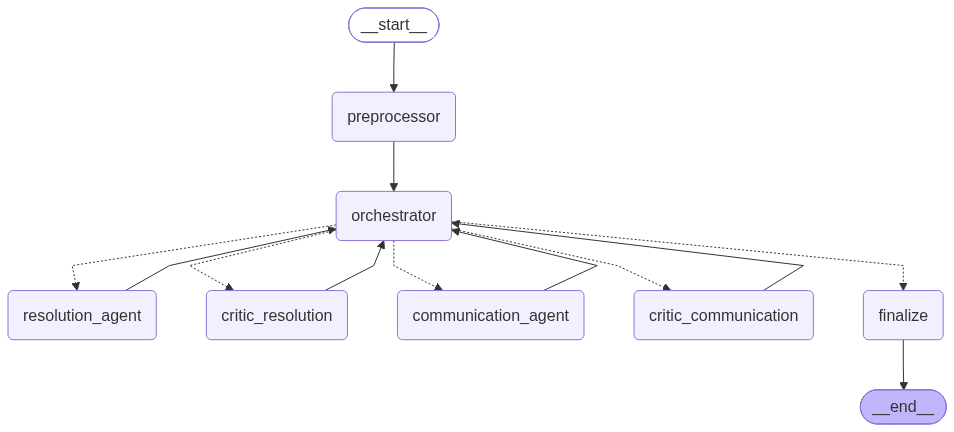

In [44]:
# Mermaid rendering uses a remote renderer in many notebook environments.
# If that renderer is unavailable, print the Mermaid source instead.
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as error:
    print(f"PNG rendering was unavailable: {error}")
    print(app.get_graph().draw_mermaid())

- Every specialist returns its result to the Orchestrator.
- This keeps routing, retry limits, and required escalations in one place instead of letting one model pass work directly to another.


# **Evaluation Metrics**

We now define the evaluation metrics for the multi-agent system.

## Task Completion Rate

This function computes task completion for a single shipment by checking three sub-criteria:
- whether the exception classification matches ground truth,
- whether the resolution action is correct, and
- whether the communication tone is appropriate.

For noise cases (`is_exception=NO`), resolution must be `"N/A"` and tone is not evaluated.

A task is complete ONLY when ALL three sub-criteria pass.

In [45]:
def compute_task_completion(gt: dict, pred: dict) -> dict:
    """Compute task completion for a single shipment."""
    res = pred.get("resolution_output", {})
    comm = pred.get("communication_output", {})

    # Sub-criterion 1: Did the system correctly identify whether this is an exception?
    exception_correct = gt.get("is_exception") == res.get("is_exception")

    if gt.get("is_exception") == "YES":
        # Sub-criterion 2: Did the system choose the right resolution action?
        resolution_correct = gt.get("expected_resolution") == res.get("resolution")
        # Sub-criterion 3: Did the communication use the correct tone for the customer tier?
        tone_correct = gt.get("expected_tone") == comm.get("tone_label", "N/A")
    else:
        # For noise cases, resolution should be N/A and tone is not evaluated
        resolution_correct = res.get("resolution") in ("N/A", None, "")
        tone_correct = True

    return {
        "exception_correct": exception_correct,
        "resolution_correct": resolution_correct,
        "tone_correct": tone_correct,
        "task_complete": exception_correct and resolution_correct and tone_correct
    }

## Escalation Accuracy

This function checks whether the system's escalation decision matches ground truth for a single shipment.
- Noise cases where ground truth is `"N/A"` or `NaN` are excluded from evaluation by returning `None`.
- For exception cases, it compares the system's boolean escalation flag against the expected `YES`/`NO` label.

In [46]:
def compute_escalation_accuracy(gt: dict, pred: dict) -> bool:
    """Check if escalation decision matches ground truth for a single shipment."""
    # Noise cases have no escalation expectation - skip evaluation
    if gt.get("should_escalate") not in ("YES", "NO"):
        return None

    # Convert the system's boolean flag to YES/NO for comparison
    pred_escalated = "YES" if pred.get("escalated", False) else "NO"

    # Compare against ground truth
    return gt.get("should_escalate") == pred_escalated

## Tool Call Accuracy

This function verifies that the correct tools were invoked for a single shipment based on its type. Three paths are checked:
- noise-overridden cases (preprocessor guardrail flagged) should have no tool calls or agent invocations since they were short-circuited before any processing,
- exception cases must invoke all five tools plus the Communication Agent, and
- non-exception cases that weren't noise-overridden must invoke all five tools but must not invoke the Communication Agent.

In [47]:
def compute_tool_call_accuracy(gt: dict, pred: dict) -> bool:
    """Check if correct tools were invoked for a single shipment."""
    # Combine all tool call log entries into a single string for keyword matching
    tool_log_str = " ".join(pred.get("tool_calls_log", []))
    is_exception = gt.get("is_exception", "NO")
    noise_override = pred.get("noise_override", False)

    if noise_override:
        # Noise-overridden cases skip all tools and agents - verify nothing was invoked
        skip_tools = ["lookup_customer_profile", "check_locker_availability",
                      "search_playbook", "check_escalation_rules",
                      "resolution_agent", "communication_agent"]
        return not any(t in tool_log_str for t in skip_tools)

    # Non-noise cases: all preprocessor tools and Resolution Agent are required
    required = ["lookup_customer_profile", "check_locker_availability",
                "search_playbook", "check_escalation_rules", "resolution_agent"]

    # Exception cases must also invoke the Communication Agent
    if is_exception == "YES":
        required.append("communication_agent")

    all_present = all(t in tool_log_str for t in required)

    # Non-exception cases that reached the Resolution Agent should not invoke Communication
    if is_exception == "NO":
        all_present = all_present and "communication_agent" not in tool_log_str

    return all_present

## Reasoning Trajectory Coherence

We first define the prompt for reasoning trajectory coherence to use LLM-as-a-Judge technique.

- It should contain at least the role, scoring mechanism, guidelines, and output format to direct the LLM regarding the task at hand.
- Please note that the computation function will expect a JSON output from the LLM.

In [48]:
class CoherenceOutput(BaseModel):
    """Typed output for the LLM-as-judge metric."""
    score: int = Field(ge=1, le=5, description="Integer coherence score from 1 to 5")
    justification: str = Field(description="Short evidence-based explanation")


REASONING_TRAJECTORY_COHERENCE_PROMPT = """
You are an impartial evaluator scoring the reasoning path of a multi-agent
delivery-exception system. You receive a JSON trace with known PII removed.

Use this integer scale:
1 = incoherent or self-contradictory
2 = major gaps, ignored tools, or ignored rules
3 = mostly ordered but weakly justified
4 = clear and policy-aware with only small issues
5 = clear, consistent path from preprocessing through tools, resolution,
    critic review, communication when needed, and finalization

Check that routine noise skips unnecessary work, exception decisions match the
available facts, revision loops are bounded, and automatic escalation triggers
are not silently dropped. Judge the trace, not whether you prefer different
wording. Return the required structured score and a 2-4 sentence justification.
"""

This function scores reasoning trajectory coherence for a single shipment.
- Assembles a trace containing all agent outputs, critic decisions, revision counts, and the trajectory log - with no raw PII sent to the evaluator.
- Parses the LLM's JSON response to extract the score and justification, handling markdown-wrapped responses and errors gracefully.

In [49]:
def compute_coherence_score(pred: dict) -> dict:
    """Score reasoning coherence with a typed judge output and redacted context."""
    state_for_redaction = pred
    event = pred.get("consolidated_event", {})
    safe_event = {
        key: value
        for key, value in event.items()
        if key not in {"customer_id", "delivery_address"}
    }
    if "status_description" in safe_event:
        safe_event["status_description"] = redact_known_pii(
            safe_event["status_description"], state_for_redaction
        )
    if "prior_attempt_notes" in safe_event:
        safe_event["prior_attempt_notes"] = [
            redact_known_pii(note, state_for_redaction)
            for note in safe_event["prior_attempt_notes"]
        ]

    safe_communication = dict(pred.get("communication_output", {}))
    if "communication_message" in safe_communication:
        safe_communication["communication_message"] = redact_known_pii(
            safe_communication["communication_message"], state_for_redaction
        )

    trace = {
        "shipment_id": pred.get("shipment_id"),
        "consolidated_event": safe_event,
        "customer_tier": pred.get("customer_profile", {}).get("tier"),
        "escalation_signals": pred.get("escalation_signals", {}),
        "resolution_output": pred.get("resolution_output", {}),
        "critic_resolution_output": pred.get("critic_resolution_output", {}),
        "resolution_revision_count": pred.get("resolution_revision_count", 0),
        "communication_output": safe_communication,
        "critic_communication_output": pred.get("critic_communication_output", {}),
        "trajectory_log": pred.get("trajectory_log", []),
    }

    structured_judge = eval_llm.with_structured_output(CoherenceOutput)
    try:
        result = structured_judge.invoke(
            [
                SystemMessage(content=REASONING_TRAJECTORY_COHERENCE_PROMPT),
                HumanMessage(content=json.dumps(trace, indent=2)),
            ]
        )
        return result.model_dump()
    except Exception as error:
        return {
            "score": 0,
            "justification": f"Coherence evaluation failed: {str(error)[:200]}",
        }

## Helper Function for Single Test Case Metrics

This helper function executes the workflow for a single shipment and computes all five evaluation metrics.
- Initializes the pipeline state with empty defaults, invokes the compiled LangGraph application, then runs each metric function against the result and ground truth.
- Also extracts playbook page citations for the test case output.

In [50]:
def run_single_test_case(shipment_id: str, rows: list[dict], gt: dict) -> dict:
    """Execute the pipeline for a single shipment and compute all metrics."""
    # Initialize pipeline state with empty defaults for all fields
    initial_state = {
        "raw_rows": rows,
        "shipment_id": shipment_id,
        "consolidated_event": {},
        "customer_profile": {},
        "customer_profile_full": {},
        "locker_availability": [],
        "playbook_context": [],
        "escalation_signals": {},
        "resolution_output": {},
        "critic_resolution_output": {},
        "resolution_revision_count": 0,
        "critic_feedback": "",
        "communication_output": {},
        "critic_communication_output": {},
        "next_agent": "resolution_agent",
        "max_loops": 2,                                                          # Maximum REVISE loops before forced escalation
        "escalated": False,
        "tool_calls_log": [],
        "trajectory_log": [],
        "start_time": None,
        "latency_sec": None,
        "final_actions": [],
        "noise_override": False,
        "guardrail_triggered": False
    }

    # Run the full pipeline
    result = app.invoke(initial_state)

    # Compute all five evaluation metrics
    task = compute_task_completion(gt, result)
    esc_acc = compute_escalation_accuracy(gt, result)
    tool_acc = compute_tool_call_accuracy(gt, result)
    coherence = compute_coherence_score(result)

    # Extract which playbook pages were referenced for citation tracking
    citations = list(dict.fromkeys(
        f"Page {c['page']}" for c in result.get("playbook_context", [])
    ))

    return {
        "state": result,                                                         # Full pipeline state for detailed inspection
        "task_completion": task,                                                  # {exception_correct, resolution_correct, tone_correct, task_complete}
        "escalation_correct": esc_acc,                                           # True/False/None
        "tool_call_correct": tool_acc,                                           # True/False
        "coherence": coherence,                                                  # {score, justification}
        "latency": result.get("latency_sec", 0.0),                              # End-to-end seconds
        "citations": citations                                                   # Playbook pages referenced
    }

# **Test Cases**

## Prepare Ground Truth

We prepares the test case inputs.
- Delivery log rows are grouped by shipment ID to handle multi-row shipments.
- Ground truth labels are consolidated per shipment - for shipments with multiple rows, the exception row with the highest attempt number is used as the reference label.
- Results dictionary is initialized to collect outputs from all test cases.

In [51]:
# Read all delivery logs and group rows by shipment ID
all_logs = read_delivery_logs.invoke({})
shipment_groups = defaultdict(list)
for row in all_logs:
    shipment_groups[row["shipment_id"]].append(row)

# Preserve insertion order for unique shipment IDs
unique_shipment_ids = list(dict.fromkeys(row["shipment_id"] for row in all_logs))

# Build consolidated ground truth - one label per shipment
gt_by_shipment = defaultdict(list)
for _, row in ground_truth_df.iterrows():
    gt_by_shipment[row["shipment_id"]].append(row.to_dict())

# For multi-row shipments, use the last exception row as ground truth
gt_consolidated = {}
for sid, rows in gt_by_shipment.items():
    exc_rows = [r for r in rows if r["is_exception"] == "YES"]
    gt_consolidated[sid] = exc_rows[-1] if exc_rows else rows[0]

print(f"Shipments to process: {unique_shipment_ids}")

# Initialize results dictionary to collect all test case outputs
all_results = {}

Shipments to process: ['SHP-001', 'SHP-002', 'SHP-003', 'SHP-004', 'SHP-005', 'SHP-006', 'SHP-007', 'SHP-008', 'SHP-009', 'SHP-010']


## Helper Function for Test Case Runs

This helper function prints the complete output for a single test case
- predictions versus ground truth,
- all five evaluation metrics,
- the full agent trajectory trace,
- playbook page citations, and
- a preview of the customer message if one was generated.

In [52]:
def format_ground_truth(value):
    """Show empty ground-truth fields as N/A in notebook output."""
    return "N/A" if pd.isna(value) else str(value)


def print_test_case_output(sid: str, result: dict, gt: dict):
    """Pretty-print a single test case result."""
    state = result["state"]
    res = state.get("resolution_output", {})
    comm = state.get("communication_output", {})
    tc = result["task_completion"]

    # --- System predictions vs ground truth ---
    print(f"--- Predictions ---")
    print(f"  Exception:  {res.get('is_exception', 'N/A')} (GT: {format_ground_truth(gt.get('is_exception'))})")
    print(f"  Resolution: {res.get('resolution', 'N/A')} (GT: {format_ground_truth(gt.get('expected_resolution'))})")
    pred_esc = 'YES' if state.get('escalated') else 'NO'
    print(f"  Escalated:  {pred_esc} (GT: {format_ground_truth(gt.get('should_escalate'))})")
    print(f"  Tone:       {comm.get('tone_label', 'N/A')} (GT: {format_ground_truth(gt.get('expected_tone'))})")
    print(f"  Revisions:  {state.get('resolution_revision_count', 0)}")
    print(f"  Guardrail:  {'TRIGGERED' if state.get('guardrail_triggered') else 'CLEAR'}")

    # --- Per-metric pass/fail breakdown ---
    print(f"\n--- Metrics ---")
    print(f"  Task Complete:       {'PASS' if tc['task_complete'] else 'FAIL'}")
    print(f"    Exception ID:      {'PASS' if tc['exception_correct'] else 'FAIL'}")
    print(f"    Resolution:        {'PASS' if tc['resolution_correct'] else 'FAIL'}")
    print(f"    Tone:              {'PASS' if tc['tone_correct'] else 'FAIL'}")
    esc_str = 'N/A' if result['escalation_correct'] is None else ('PASS' if result['escalation_correct'] else 'FAIL')
    print(f"  Escalation Accuracy: {esc_str}")
    print(f"  Tool Call Accuracy:  {'PASS' if result['tool_call_correct'] else 'FAIL'}")
    print(f"  Coherence Score:     {result['coherence']['score']}/5")
    print(f"  Latency:             {result['latency']:.2f}s")

    # --- Full agent decision trail ---
    print(f"\n--- Trajectory ---")
    for entry in state.get("trajectory_log", []):
        print(f"  {entry}")

    # --- Which playbook pages were retrieved ---
    print(f"\n--- Document Citations ---")
    print(f"  Playbook pages referenced: {', '.join(result['citations']) if result['citations'] else 'None'}")

    # --- Preview of the customer notification if generated ---
    if comm.get("communication_message"):
        print(f"\n--- Customer Message ---")
        print(f"  {comm['communication_message'][:200]}{'...' if len(comm.get('communication_message','')) > 200 else ''}")

## Test Case 1: SHP-001 - Successful Delivery (Noise Filtering)

In [53]:
sid = "SHP-001"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: N/A)
  Escalated:  NO (GT: N/A)
  Tone:       N/A (GT: N/A)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             0.00s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  preprocessor: DELIVERED flagged as noise by guardrail, skipping tool calls
  orchestrator: noise override; skipped all LLM agents
  finalize: actions={"shipment_id": "SHP-001", "is_exception": "NO", "resolution": "N/A", "escalated": false, "tone": "N/A", "revision_count": 0, "guardrail_blocked": false, "message_generated": false}; latency=0.001s

--- Document Citations ---
  Playbook pages referenced: None


- SHP-001 is a completed delivery with no problem reported.
- The expected result is NO / N/A, no operational tools or model calls, no customer message, and almost no processing time.


## Test Case 2: SHP-002 - VIP Multi-Attempt with Duplicate Scan

In [54]:
sid = "SHP-002"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             5.93s

--- Trajectory ---
  preprocessor: 3 raw rows -> 2 after dedup
  orchestrator: automatic escalation enforced - ['AUTOMATIC: VIP customer with 5 exceptions in 90d (>=3)']
  resolution_agent: no eligible locker; changed action to RESCHEDULE
  resolution_agent: is_exception=YES, resolution=RESCHEDULE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=FORMAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-002", "is_exception": "YES", "resolution": "RESCHEDULE", "escalated": true, "tone": "FORMAL", "revision_count": 0, "

- SHP-002 contains two actual failed attempts and one duplicate scan.
- The duplicate should be removed, the latest attempt should be used, the full locker should lead to RESCHEDULE, and the VIP history should cause an escalation with a FORMAL message.


## Test Case 3: SHP-003 - Address Not Found (Standard Customer)

In [55]:
sid = "SHP-003"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  NO (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             4.48s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RESCHEDULE
  critic_resolution: address verification and RESCHEDULE accepted
  critic_resolution: decision=ACCEPT
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-003", "is_exception": "YES", "resolution": "RESCHEDULE", "escalated": false, "tone": "CASUAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=4.482s

--- Document Citations ---
  Playbook page

- SHP-003 requires address verification followed by RESCHEDULE.
- The customer is STANDARD and has no history-based trigger, so the expected tone is CASUAL and the case should not be escalated.


## Test Case 4: SHP-004 - Damaged Fragile Package (VIP Escalation)

In [56]:
sid = "SHP-004"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             5.18s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  orchestrator: automatic escalation enforced - ['AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3)']
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=FORMAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-004", "is_exception": "YES", "resolution": "REPLACE", "escalated": true, "tone": "FORMAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=5.181s

--- Docume

- SHP-004 is a crushed FRAGILE package for a VIP customer.
- The damage rule makes REPLACE the expected action, with a FORMAL message and escalation.


## Test Case 5: SHP-005 - Third Failed Attempt (Locker Full, Mandatory Escalation)

In [57]:
sid = "SHP-005"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REROUTE_TO_LOCKER (GT: REROUTE_TO_LOCKER)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             5.78s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  orchestrator: automatic escalation enforced - ['AUTOMATIC: 3rd failed delivery attempt']
  resolution_agent: is_exception=YES, resolution=REROUTE_TO_LOCKER
  critic_resolution: decision=ESCALATE
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-005", "is_exception": "YES", "resolution": "REROUTE_TO_LOCKER", "escalated": true, "tone": "CASUAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; la

- SHP-005 must be escalated because it is the third failed attempt.
- The course label expects REROUTE_TO_LOCKER, but the only nearby locker is FULL and the playbook says not to use it.
- The action is treated as a supervisor-managed pickup or reroute category, not as approval to place the package in the full locker.


## Test Case 6: SHP-006 - Refused Delivery (Return to Sender)

In [58]:
sid = "SHP-006"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: RETURN_TO_SENDER)
  Escalated:  NO (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             4.91s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RETURN_TO_SENDER
  critic_resolution: decision=ACCEPT
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-006", "is_exception": "YES", "resolution": "RETURN_TO_SENDER", "escalated": false, "tone": "CASUAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=4.913s

--- Document Citations ---
  Playbook pages referenced: Page 5, Page 2

--- Customer

- SHP-006 is a refused delivery.
- The expected action is RETURN_TO_SENDER with a CASUAL message and no escalation because no escalation rule applies.


## Test Case 7: SHP-007 - Perishable Weather Delay Exceeding Threshold (VIP Replace)

In [59]:
sid = "SHP-007"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             5.42s

--- Trajectory ---
  preprocessor: 2 raw rows -> 1 after dedup
  orchestrator: automatic escalation enforced - ['AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold)']
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=FORMAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-007", "is_exception": "YES", "resolution": "REPLACE", "escalated": true, "tone": "FORMAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=5.423s

--- Docum

- SHP-007 contains a duplicate weather scan.
- After the duplicate is removed, the five-hour delay on a PERISHABLE package calls for REPLACE, a FORMAL message, and automatic escalation.


## Test Case 8: SHP-008 - Discretionary Escalation (High Exception History)

In [60]:
sid = "SHP-008"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             4.70s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RESCHEDULE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-008", "is_exception": "YES", "resolution": "RESCHEDULE", "escalated": true, "tone": "CASUAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=4.701s

--- Document Citations ---
  Playbook pages referenced: Page 2, Page 3, Page 5

--- Customer Message ---


- SHP-008 is a second failed attempt for a STANDARD customer with six recent exceptions.
- The full locker makes RESCHEDULE the practical action, while the repeated exception history supports escalation and a CASUAL message.


## Test Case 9: SHP-009 - Severely Damaged Perishable (Premium Replace)

In [61]:
sid = "SHP-009"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             5.56s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  orchestrator: automatic escalation enforced - ['AUTOMATIC: Damaged perishable package']
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=FORMAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-009", "is_exception": "YES", "resolution": "REPLACE", "escalated": true, "tone": "FORMAL", "revision_count": 0, "guardrail_blocked": false, "message_generated": true}; latency=5.562s

--- Document Citations ---


- SHP-009 is a leaking and likely spoiled PERISHABLE package.
- It should not be delivered. The expected result is REPLACE, a FORMAL message for the PREMIUM customer, and automatic escalation.


## Test Case 10: SHP-010 - Routine Depot Scan (Noise Filtering)

In [62]:
sid = "SHP-010"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: N/A)
  Escalated:  NO (GT: N/A)
  Tone:       N/A (GT: N/A)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             0.00s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  preprocessor: SCANNED flagged as noise by guardrail, skipping tool calls
  orchestrator: noise override; skipped all LLM agents
  finalize: actions={"shipment_id": "SHP-010", "is_exception": "NO", "resolution": "N/A", "escalated": false, "tone": "N/A", "revision_count": 0, "guardrail_blocked": false, "message_generated": false}; latency=0.001s

--- Document Citations ---
  Playbook pages referenced: None


- SHP-010 is a routine depot scan.
- It should be filtered before any tool or model calls, with NO / N/A, no customer message, and almost no processing time.


# **Aggregated Evaluation Metrics**

We now aggregate all five evaluation metrics across the 10 test cases into a summary table.

- Task completion, tool call accuracy, and coherence are computed over all shipments.
- Escalation accuracy excludes noise cases where ground truth is `"N/A"`.
- Latency is reported as the mean across all runs.

In [63]:
# Put every shipment on one row before calculating the five headline metrics
aggregate_rows = []
for sid, result in all_results.items():
    task = result["task_completion"]
    aggregate_rows.append(
        {
            "shipment_id": sid,
            "task_complete": task["task_complete"],
            "exception_correct": task["exception_correct"],
            "resolution_correct": task["resolution_correct"],
            "tone_correct": task["tone_correct"],
            "escalation_correct": result["escalation_correct"],
            "tool_call_correct": result["tool_call_correct"],
            "coherence": result["coherence"]["score"],
            "latency_sec": result["latency"],
        }
    )

aggregate_df = pd.DataFrame(aggregate_rows)
escalation_cases = aggregate_df["escalation_correct"].dropna()

summary = pd.DataFrame(
    [
        {
            "Metric": "Task Completion Rate",
            "Value": (
                f"{aggregate_df['task_complete'].mean():.1%} "
                f"({int(aggregate_df['task_complete'].sum())}/{len(aggregate_df)})"
            ),
        },
        {
            "Metric": "Escalation Accuracy",
            "Value": (
                f"{escalation_cases.mean():.1%} "
                f"({int(escalation_cases.sum())}/{len(escalation_cases)} exception cases)"
            ),
        },
        {
            "Metric": "Tool Call Accuracy",
            "Value": f"{aggregate_df['tool_call_correct'].mean():.1%}",
        },
        {
            "Metric": "Reasoning Coherence (Average)",
            "Value": f"{aggregate_df['coherence'].mean():.2f}/5.0",
        },
        {
            "Metric": "Latency (Average)",
            "Value": f"{aggregate_df['latency_sec'].mean():.2f}s",
        },
    ]
)

print("AGGREGATED EVALUATION SUMMARY")
display(summary)

AGGREGATED EVALUATION SUMMARY


,Metric,Value
0,Task Completion Rate,100.0% (10/10)
1,Escalation Accuracy,100.0% (8/8 exception cases)
2,Tool Call Accuracy,100.0%
3,Reasoning Coherence (Average),4.70/5.0
4,Latency (Average),4.20s


- This table summarizes the current run.
- Escalation accuracy uses the eight exception cases because the two routine cases have no ground-truth escalation value.
- The results are useful for checking this small test set, but they do not guarantee the same performance in production.


We print the detailed per-shipment results showing ground truth versus predictions for each evaluation dimension, along with pass/fail status for task completion and tool calls, the coherence score, and latency.

This provides a complete at-a-glance view of where the system succeeded and where it diverged.

In [64]:
# Compare each prediction with the consolidated shipment-level ground truth
detail_rows = []
for sid in unique_shipment_ids:
    result = all_results[sid]
    state = result["state"]
    ground_truth = gt_consolidated[sid]
    resolution = state.get("resolution_output", {})
    communication = state.get("communication_output", {})
    expected_escalation = ground_truth.get("should_escalate")
    predicted_escalation = "YES" if state.get("escalated") else "NO"

    detail_rows.append(
        {
            "Shipment": sid,
            "Status": state.get("consolidated_event", {}).get("status_code", "N/A"),
            "Exception (GT/Pred)": (
                f"{format_ground_truth(ground_truth.get('is_exception'))}/"
                f"{resolution.get('is_exception', 'ERROR')}"
            ),
            "Resolution (GT/Pred)": (
                f"{format_ground_truth(ground_truth.get('expected_resolution'))}/"
                f"{resolution.get('resolution', 'ERROR')}"
            ),
            "Escalation (GT/Pred)": (
                f"{format_ground_truth(expected_escalation)}/"
                f"{predicted_escalation if expected_escalation in ('YES', 'NO') else 'N/A'}"
            ),
            "Tone (GT/Pred)": (
                f"{format_ground_truth(ground_truth.get('expected_tone'))}/"
                f"{communication.get('tone_label', 'N/A')}"
            ),
            "Task": "PASS" if result["task_completion"]["task_complete"] else "FAIL",
            "Tools": "PASS" if result["tool_call_correct"] else "FAIL",
            "Coherence": result["coherence"]["score"],
            "Latency": f"{result['latency']:.2f}s",
            "Playbook pages": ", ".join(result["citations"]) or "None",
        }
    )

detail_df = pd.DataFrame(detail_rows)
display(detail_df)

print("Coherence justifications:")
for sid, result in all_results.items():
    print(f"- {sid}: {result['coherence'].get('justification', '')}")

,Shipment,Status,Exception (GT/Pred),Resolution (GT/Pred),Escalation (GT/Pred),Tone (GT/Pred),Task,Tools,Coherence,Latency,Playbook pages
0,SHP-001,DELIVERED,NO/NO,N/A/N/A,N/A/N/A,N/A/N/A,PASS,PASS,5,0.00s,None
1,SHP-002,ATTEMPTED,YES/YES,RESCHEDULE/RESCHEDULE,YES/YES,FORMAL/FORMAL,PASS,PASS,4,5.93s,"Page 5, Page 9, Page 2"
2,SHP-003,ADDRESS_ISSUE,YES/YES,RESCHEDULE/RESCHEDULE,NO/NO,CASUAL/CASUAL,PASS,PASS,5,4.48s,"Page 3, Page 2"
3,SHP-004,DAMAGED,YES/YES,REPLACE/REPLACE,YES/YES,FORMAL/FORMAL,PASS,PASS,5,5.18s,"Page 4, Page 6"
4,SHP-005,ATTEMPTED,YES/YES,REROUTE_TO_LOCKER/REROUTE_TO_LOCKER,YES/YES,CASUAL/CASUAL,PASS,PASS,4,5.78s,"Page 2, Page 3, Page 10"
5,SHP-006,REFUSED,YES/YES,RETURN_TO_SENDER/RETURN_TO_SENDER,NO/NO,CASUAL/CASUAL,PASS,PASS,5,4.91s,"Page 5, Page 2"
6,SHP-007,WEATHER_DELAY,YES/YES,REPLACE/REPLACE,YES/YES,FORMAL/FORMAL,PASS,PASS,5,5.42s,Page 6
7,SHP-008,ATTEMPTED,YES/YES,RESCHEDULE/RESCHEDULE,YES/YES,CASUAL/CASUAL,PASS,PASS,4,4.70s,"Page 2, Page 3, Page 5"
8,SHP-009,DAMAGED,YES/YES,REPLACE/REPLACE,YES/YES,FORMAL/FORMAL,PASS,PASS,5,5.56s,"Page 6, Page 4, Page 3"
9,SHP-010,SCANNED,NO/NO,N/A/N/A,N/A/N/A,N/A/N/A,PASS,PASS,5,0.00s,None


Coherence justifications:
- SHP-001: The trace demonstrates a clear and consistent reasoning path. The preprocessing step correctly identifies the 'DELIVERED' status as routine noise, leading to the decision to skip unnecessary tool calls. The resolution output aligns with the facts, indicating no exception due to the absence of anomaly wording. The process avoids unnecessary escalation and communication, adhering to policy guidelines. The trajectory log confirms the efficient handling of the event, with no revision loops or dropped escalation triggers, resulting in a coherent and justified resolution.
- SHP-002: The trace demonstrates a clear and consistent reasoning path. The system correctly identifies the delivery as an exception due to the VIP status and history of exceptions, triggering an automatic escalation. The resolution agent initially opts for rescheduling due to a full locker, but the critic correctly identifies the need for escalation to a supervisor, aligning with polic

- This table compares the prediction and ground truth for every shipment.
- A failed row shows whether the difference came from classification, action, tone, escalation, tool use, retrieval, or the coherence review.
- SHP-005 should still be reviewed as a policy and label conflict even when the row passes the numeric checks.


Finally, we close the database connection.

In [65]:
db_conn.close()

# **Conclusions and Business Recommendations**

## Conclusions

- The notebook shows a complete workflow with data preparation, policy retrieval, resolution, customer communication, review checks, and final routing.
- Routine DELIVERED and SCANNED events stop before tool or model calls. This is the main cost-saving path because normal events do not need the exception workflow.
- Duplicate scans are removed before a decision is made, and required escalation rules are handled in code. A model recommendation cannot turn off a third-attempt, VIP-history, damaged-perishable, long perishable-delay, or fraud trigger.
- The 10 supplied shipments are a small and visible test set. The summary table describes this run only and does not prove production accuracy or remove normal model variation.
- SHP-005 exposes a limitation in the course data. The ground-truth label says REROUTE_TO_LOCKER, while the playbook says a full locker cannot be used and a third attempt should normally be held at the depot. The current action list has no HOLD_AT_DEPOT option, so REROUTE_TO_LOCKER is treated as a supervisor-managed placeholder and the notebook does not claim that the full locker was selected.


## Business Recommendations

- Start with a supervised trial. Let the system prepare the case, recommendation, trace, and draft message, but keep a dispatcher involved in every escalation until real operating data supports wider use.
- Fix the policy and label mismatch before production. Add HOLD_AT_DEPOT to the action list, update the SHP-005 ground truth, and allow more than one correct action when the playbook gives the customer a choice.
- Expand and separate the evaluation data. Add missing customers, corrupt rows, conflicting scans, borderline weather delays, eligible and ineligible lockers, and prompt-injection attempts. Keep a hidden validation set so changes are not tuned to the same 10 answers.
- Treat the keyword injection check as an initial filter, not complete security. Add a stronger meaning-based check and continue using typed outputs, required escalation rules, PII removal, and human review.
- Measure business results during the trial. Track repeat truck trips, spoilage avoided, dispatcher time saved, supervisor overrides, response time, API cost, and customer complaints. These results should decide whether the workflow creates value; the notebook accuracy score alone is not enough.


## Run and export checklist

- Place config.json beside the notebook. LangSmith is optional.
- Run the install cell once, restart the Colab runtime, and then use Run all from the import cell onward.
- Confirm that all 10 shipment sections and both summary tables contain output and no cell shows an error.
- Download the executed Project_3_Full_Code_solution.ipynb file and export it with jupyter nbconvert --to html Project_3_Full_Code_solution.ipynb.
- Open the HTML file and confirm that the outputs, conclusions, and business recommendations are visible before submitting it.


<font size=6 color='#4682B4'>Power Ahead</font>
___